[Data in Kaggle](https://www.kaggle.com/heesoo37/120-years-of-olympic-history-athletes-and-results?select=athlete_events.csv)

# Import the libraries

In [1]:
import numpy as np
import pandas as pd

# Read the data

In [2]:
# Read the first csv file
df1 = pd.read_csv("athlete_events.csv")

# Read the second csv file
df2 = pd.read_csv("noc_regions.csv")

In [3]:
df1.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [4]:
df2.head()

,NOC,region,notes
0,AFG,Afghanistan,NaN
1,AHO,Curacao,Netherlands Antilles
2,ALB,Albania,NaN
3,ALG,Algeria,NaN
4,AND,Andorra,NaN


### Don't forget to drop duplicates first

In [5]:
# Count duplicates before removing them
print("df1 duplicates:",df1.duplicated().sum())
print("df2 duplicates:",df2.duplicated().sum())

# Remove duplicates
df1 = df1.drop_duplicates()
df2 = df2.drop_duplicates()

# Count duplicates after removing them
print("df1 duplicates:",df1.duplicated().sum())
print("df2 duplicates:",df2.duplicated().sum())

df1 duplicates: 1385
df2 duplicates: 0
df1 duplicates: 0
df2 duplicates: 0


# <font color='red'>**Beginner level**</font>

### Find the missing data in each column

In [6]:
df1_missing = df1.isna().sum()
df1_missing[df1_missing>0]

,0
Age,9315
Height,58814
Weight,61527
Medal,229959


In [7]:
df2_missing = df2.isna().sum()
df2_missing[df2_missing>0]

,0
region,3
notes,209


### Number of males and females

In [8]:
count_sex = df1['Sex'].value_counts()
count_sex

,count
Sex,
M,195353
F,74378


### How many cities do we have and what are they ?

In [9]:
print("Number of unique cities:", df1['City'].nunique())

print("Names of the cities:\n", df1['City'].unique())

Number of unique cities: 42
Names of the cities:
 ['Barcelona' 'London' 'Antwerpen' 'Paris' 'Calgary' 'Albertville'
 'Lillehammer' 'Los Angeles' 'Salt Lake City' 'Helsinki' 'Lake Placid'
 'Sydney' 'Atlanta' 'Stockholm' 'Sochi' 'Nagano' 'Torino' 'Beijing'
 'Rio de Janeiro' 'Athina' 'Squaw Valley' 'Innsbruck' 'Sarajevo'
 'Mexico City' 'Munich' 'Seoul' 'Berlin' 'Oslo' "Cortina d'Ampezzo"
 'Melbourne' 'Roma' 'Amsterdam' 'Montreal' 'Moskva' 'Tokyo' 'Vancouver'
 'Grenoble' 'Sapporo' 'Chamonix' 'St. Louis' 'Sankt Moritz'
 'Garmisch-Partenkirchen']


# <font color='red'>**Intermediate level**</fond>

### Find the number of athlete for each year

In [10]:
num_ath_by_year = df1['Year'].value_counts()
num_ath_by_year

,count
Year,
1992,16413
1988,14676
2000,13821
1996,13780
2016,13688
2008,13602
2004,13443
2012,12920
1972,11959


### Which athlete participated the most? (his/her name and ID)

In [11]:
name_id = df1[['ID', 'Name']].value_counts().head(1)
name_id

,,count
ID,Name,
106296,Heikki Ilmari Savolainen,39


# <font color='red'>**Advanced level**</fond>

### Find the number of each medal for each year.
##### The output should look like this
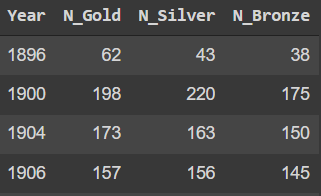

In [ ]:
pd.crosstab(df1['Year'], df1['Medal'])

Medal,Bronze,Gold,Silver
Year,,,
1896,38,62,43
1900,175,198,220
1904,150,173,163
1906,145,157,156
1908,256,294,281
1912,300,326,315
1920,367,493,448
1924,311,332,319
1928,281,275,267


# <font color='red'>**You are Geek!**</fond>
### Provide all your answers with plots

### Find the number of winners with the gold medal in each city?

In [ ]:
gold_city = df1[df1['Medal'] == 'Gold']['City'].value_counts()
gold_city

,count
City,
London,1215
Athina,883
Los Angeles,726
Beijing,671
Rio de Janeiro,665
Sydney,663
Atlanta,608
Barcelona,559
Seoul,520


<Axes: title={'center': 'Gold Medal Winners per City'}, xlabel='City'>

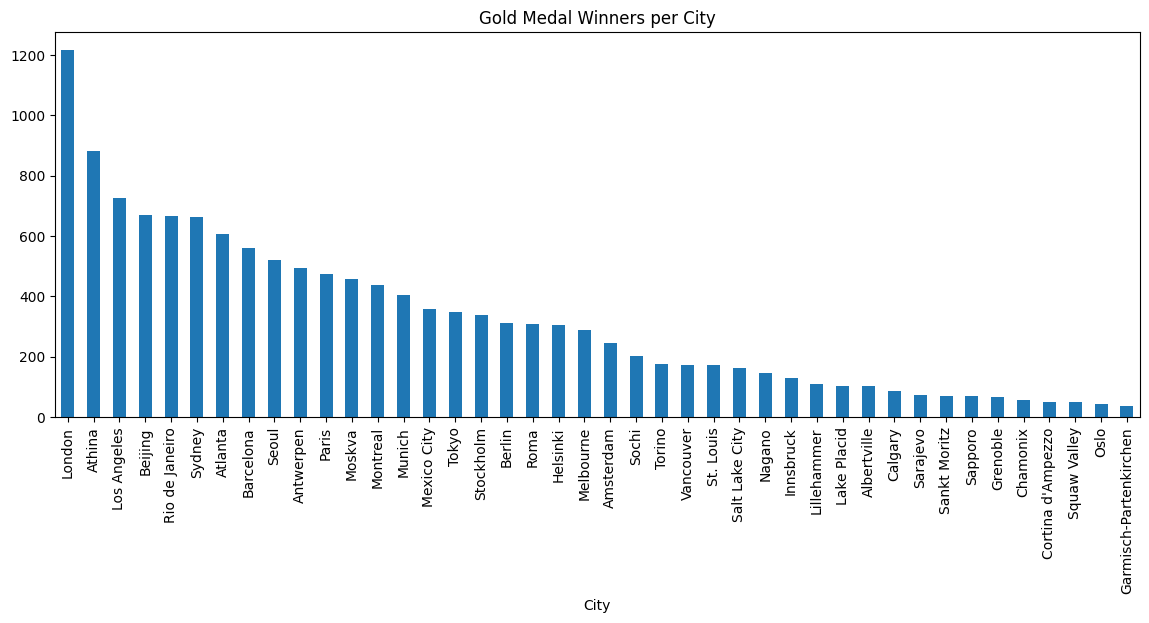

In [ ]:
gold_city.plot(kind='bar', figsize=(14, 5), title='Gold Medal Winners per City')

### Find the total missing data for each year?

In [ ]:
missing = df1.isna().groupby(df1['Year']).sum()

<Axes: title={'center': 'Missing Data per Year'}, xlabel='Year'>

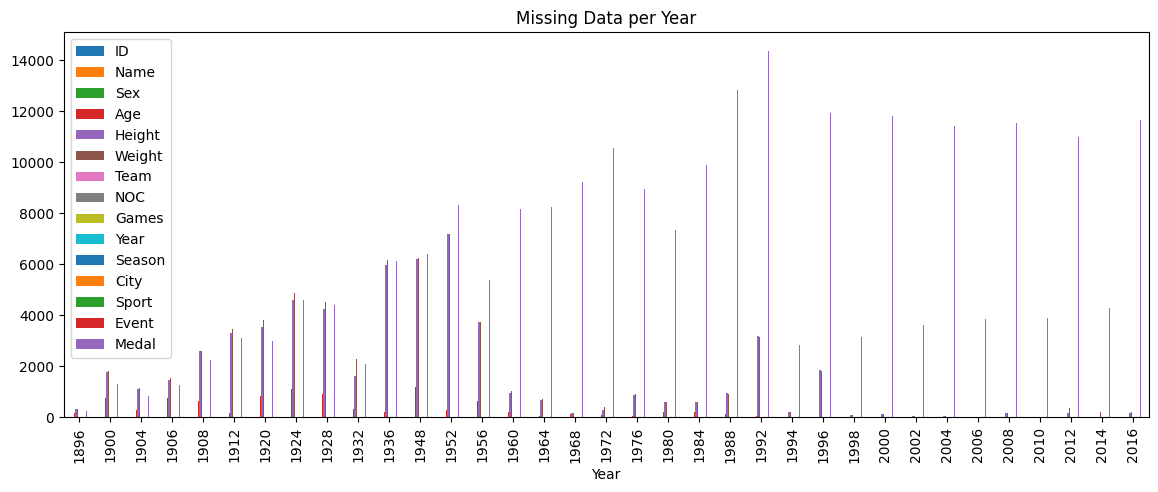

In [ ]:
missing.plot(kind='bar', figsize=(14, 5), title='Missing Data per Year')

# <font color='red'>**I dare you to solve this :)**</fond>
### Dont use for loops, and provide all your answers with plots.

### Has the number of athletes changed over time for Summer and Winter?

In [ ]:
athletes = df1.groupby(['Year', 'Season'])['ID'].nunique().unstack()

<Axes: title={'center': 'Number of Athletes Over Time'}, xlabel='Year'>

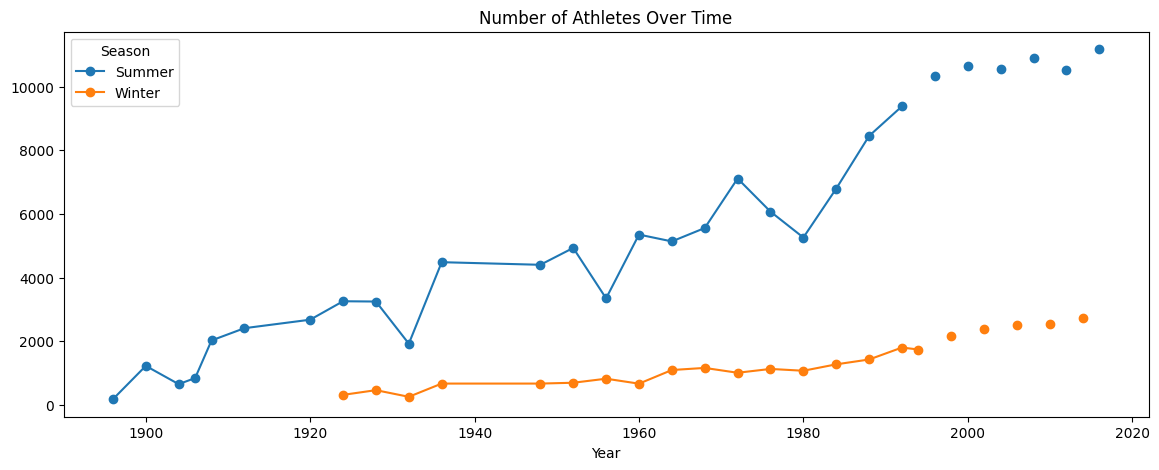

In [ ]:
athletes.plot(marker='o', figsize=(14, 5), title='Number of Athletes Over Time')